In [79]:
import sys
from pathlib import Path
sys.path[:0] = [str(Path.cwd().parent)]

import numpy as np
import matplotlib.pyplot as plt

from scripts.Hamiltonian import Hamiltonian
from scripts.Lattice import Lattice
from scripts.partial_sc import partial_sc


In [80]:
V_prime_arr = np.linspace(0.5, 2, 20)
# V_prime_arr = np.linspace(0.0, 0.42105263, 8)
nfpfn_arr = np.zeros_like(V_prime_arr)
sfpfs_arr = np.zeros_like(V_prime_arr)
dfpfd_arr = np.zeros_like(V_prime_arr)

# NFPFN

In [81]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1
T = 0.001

muD = 1.2 * t
muP = 1.8 * t
muF = 1.4 * t

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = +h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 0 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2

In [82]:
for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)
    

    partial_sc(H, temperature=T,
                atol=1e-6, rtol=1e-3, maxiter=500,
                verbose=False)
    F, Fuu, Fdd = H.get_correlations()
    nfpfn_arr[i] = np.real(Fuu.px)[int(widthD+widthF+widthP/2)-1]

Converged after 43 iterations
Converged after 55 iterations
Converged after 74 iterations
Converged after 107 iterations
Converged after 180 iterations
Converged after 88 iterations
Converged after 58 iterations
Converged after 66 iterations
Converged after 79 iterations
Converged after 96 iterations
Converged after 119 iterations
Converged after 155 iterations
Converged after 210 iterations
Converged after 309 iterations
Converged after 367 iterations
Converged after 150 iterations
Converged after 120 iterations


In [83]:
print("nfpfn_arr:", nfpfn_arr)

nfpfn_arr: [ 6.99872242e-18  6.60265900e-18  5.80890713e-18  2.65045429e-18
 -7.24002476e-18 -1.40012819e-18 -2.30131120e-17  1.29568281e-14
  3.43829681e-14  3.72245184e-14  4.94568398e-14  8.29834987e-14
  1.00575142e-13  1.61056101e-13  2.29041207e-13  1.19110699e-12
  2.43502414e-06  1.46969256e-02  2.88618577e-02  3.76236180e-02]


In [84]:
#     os.makedirs("data/DFPFD", exist_ok=True)
#     np.savez(
#     f"data/DFPFD/temp_{idx:04d}.npz",
#     idx=idx,
#     temp=temp,
#     converged=H.converged,
#     F0=F0[int(widthD+widthF+widthP/2)-1],
#     F_swave=F.swave[int(widthD+widthF+widthP/2)-1],
#     F_dwave=F.dwave[int(widthD+widthF+widthP/2)-1],
#     F_px=F.px[int(widthD+widthF+widthP/2)-1],
#     F_py=F.py[int(widthD+widthF+widthP/2)-1],
#     Fuu_px=Fuu.px[int(widthD+widthF+widthP/2)-1],
#     Fuu_py=Fuu.py[int(widthD+widthF+widthP/2)-1],
#     Fdd_px=Fdd.px[int(widthD+widthF+widthP/2)-1],
#     Fdd_py=Fdd.py[int(widthD+widthF+widthP/2)-1],
# )

# SFPFS 

In [85]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1
T = 0.001

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t
muN = 1.2 * t
mu = np.zeros(lattice.X)
mu[:widthD] = muN
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muN

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


V = None

U0 = 1.5 * t
U = U0 * np.ones(lattice.X)
U[widthD:-widthD] = 0
U[widthD-1] = U0/2
U[-widthD] = U0/2

for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F0_init=0.12,
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F0"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=1e-6, rtol=1e-3, maxiter=500)
    F, Fuu, Fdd = H.get_correlations()
    sfpfs_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("sfpfs_arr:", sfpfs_arr)


Converged after 20 iterations
Converged after 23 iterations
Converged after 26 iterations
Converged after 30 iterations
Converged after 34 iterations
Converged after 41 iterations
Converged after 49 iterations
Converged after 61 iterations
Converged after 78 iterations
Converged after 109 iterations
Converged after 173 iterations
Converged after 401 iterations
Converged after 319 iterations
Converged after 163 iterations
Converged after 126 iterations
Converged after 109 iterations
Converged after 103 iterations
Converged after 100 iterations
Converged after 100 iterations
Converged after 100 iterations
sfpfs_arr: [0.00499701 0.00541971 0.00591037 0.00648476 0.00716325 0.00797227
 0.00894608 0.01012883 0.0115763  0.01335628 0.01554537 0.01821924
 0.02135182 0.02452827 0.02773256 0.03104234 0.03450152 0.03812247
 0.04189749 0.04580467]


In [86]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1
T = 0.001

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 4 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2


for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F_init=[0.23, 0.23, -0.23, -0.23],
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F_xplus", "F_xmin", "F_yplus", "F_ymin"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=1e-6, rtol=1e-3, maxiter=500)
    F, Fuu, Fdd = H.get_correlations()
    dfpfd_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("dfpfd_arr:", dfpfd_arr)

Converged after 22 iterations
Converged after 25 iterations
Converged after 29 iterations
Converged after 35 iterations
Converged after 43 iterations
Converged after 60 iterations
Converged after 75 iterations
Converged after 91 iterations
Converged after 154 iterations
Converged after 328 iterations
Converged after 178 iterations
Converged after 140 iterations
Converged after 121 iterations
Converged after 107 iterations
Converged after 99 iterations
Converged after 95 iterations
Converged after 94 iterations
Converged after 93 iterations
Converged after 102 iterations
dfpfd_arr: [0.00556548 0.00605609 0.00662323 0.00728347 0.00805771 0.00897223
 0.01005952 0.01135864 0.01291561 0.01478408 0.0170237  0.0196201
 0.02250514 0.02556036 0.0287137  0.03196522 0.03533994 0.03885597
 0.04251598 0.04630889]


In [87]:
np.savez(
    f"data3.npz",
    V_prime_arr=V_prime_arr,
    nfpfn_arr=nfpfn_arr,
    sfpfs_arr=sfpfs_arr,
    dfpfd_arr=dfpfd_arr
)

In [91]:
data1 = np.load("data3.npz")
data2 = np.load("data2.npz")

V_prime_arr = np.concatenate([data2['V_prime_arr'], data1['V_prime_arr']])
nfpfn_arr = np.concatenate([data2['nfpfn_arr'], data1['nfpfn_arr']])
sfpfs_arr = np.concatenate([data2['sfpfs_arr'], data1['sfpfs_arr']])
dfpfd_arr = np.concatenate([data2['dfpfd_arr'], data1['dfpfd_arr']])

order = np.argsort(V_prime_arr)
V_prime_arr = V_prime_arr[order]
nfpfn_arr = nfpfn_arr[order]
sfpfs_arr = sfpfs_arr[order]
dfpfd_arr = dfpfd_arr[order]
print(order)


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]


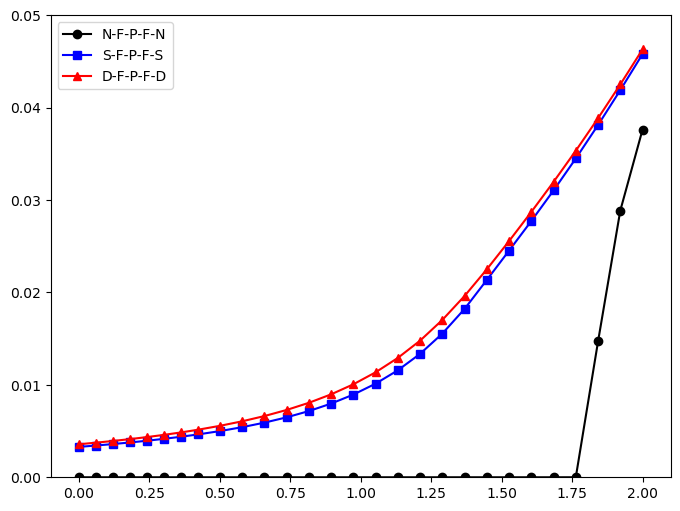

In [92]:
plt.figure(figsize=(8, 6))
plt.plot(V_prime_arr, nfpfn_arr, '-o', label="N-F-P-F-N", color='black')
plt.plot(V_prime_arr, sfpfs_arr, '-s', label="S-F-P-F-S", color='blue')
plt.plot(V_prime_arr, dfpfd_arr, '-^', label="D-F-P-F-D", color='red')
# plt.xlim(0.5, 2)
plt.ylim(0, 0.05)
plt.legend()

In [90]:
print("FINISHED!")

FINISHED!


In [3]:
import numpy as np 
temps = np.arange(0.001, 0.15 + 1e-12, 0.0005)
print(temps.shape)
# 239 temps total

(299,)


In [ ]:
temps = np.concatenate([
    np.arange(0.001, 0.1400 + 1e-12, 0.0005),
    np.arange(0.145, 0.200 + 1e-12, 0.005),
])  # 291 temps total
print(temps.shape)

(291,)
